# Reto básico 2: feature engineering

**Objetivo:** seleccionar y preparar las variables que alimentarán el K-Means, pensando como analista de negocio.

**Entrada:** `data/processed/clientes.csv`, la vista por cliente generada en el reto 1 (una fila por cliente, ya
sin nulos).

**Salidas:**
- `data/processed/features_modelo.csv`: matriz de features transformada y escalada, la entrada del clustering.
- `data/processed/clientes_modelo.csv`: features legibles (sin escalar) y grupo de cada cliente, para el perfilado.

Contenido:
1. Población a segmentar.
2. Selección justificada de features.
3. Features derivadas.
4. Tratamiento de categóricas y numéricas.
5. Pipeline que encapsula todo el proceso.

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Especificaciones_proyecto.md").exists())
PROC = ROOT / "data" / "processed"
FIG = ROOT / "modelo" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]
DIV = ["#e34948", "#f0efec", "#2a78d6"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_md(text):
    display(Markdown(text))

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

clientes = pd.read_csv(PROC / "clientes.csv", dtype={"client_id": str}).set_index("client_id")
print(clientes.shape)
clientes.head(3).T

(173456, 49)


client_id,000144e39c02702f821f69beeb7036f40cf8505051050f38ea776337ef9b6f3c,0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fabd499647aba8e3a8d8a,00046586c51084441db2d37ad19472cda98a6552323fab6179494687beae03db
age_range,35-44,25-34,65+
gender_derived,female,male,male
country_code,AT,CH,AT
months_as_mb_customer,36.000,49.000,50.000
months_is_36_spike,True,False,False
currently_connected_vehicles,1,1,1
finance_leasing_status,never_active,never_active,never_active
consent_phone_communication_channel,False,False,True
consent_epost_communication_channel,True,True,True
consent_post_communication_channel,False,True,True


## 1. Población a segmentar

El EDA detectó **833 "clientes" con más de 20 relaciones**. Solo el 10 % de sus vehículos es actual y su
comportamiento es el de concesionarios, rent-a-car o flotas registrados como particulares. Mezclarlos con los
particulares distorsionaría los centroides: un cliente con 561 relaciones es un outlier extremo en casi todas las
variables.

**Decisión:** se excluyen del entrenamiento y forman un segmento propio, **"Flota / Profesional"**, que se
describe en el reto 4. El resto (B2C y los pocos conductores B2B) se segmenta con K-Means.

In [3]:
UMBRAL_FLOTA = 20
clientes["grupo"] = np.where(clientes.n_relaciones > UMBRAL_FLOTA, "flota_profesional", "segmentable")
display(clientes.grupo.value_counts().rename("clientes").to_frame()
        .assign(pct=lambda d: d.clientes / d.clientes.sum() * 100))
seg = clientes[clientes.grupo == "segmentable"].copy()

,clientes,pct
grupo,,
segmentable,172623,99.520
flota_profesional,833,0.480


## 2. Selección justificada de features

Se buscan variables que describan **quién es el cliente, qué relación tiene con la marca, qué conduce y cómo lo
usa**, que son las cuatro palancas de las campañas del reto: ofertas de vehículo, mantenimiento, fidelización y
comunicación.

**Features del modelo (14):**

| # | Feature | Origen | Por qué se incluye |
|---|---|---|---|
| 1 | `edad_ord` | `age_range` (ordinal 0–5) | Etapa vital: condiciona el tipo de vehículo, la financiación y el canal |
| 2 | `meses_cliente` | `months_as_mb_customer` | Antigüedad y fidelidad con la marca conectada |
| 3 | `n_vehiculos_actuales` | `currently_connected_vehicles` (log, tope 5) | Valor del cliente y potencial multi-vehículo |
| 4 | `tiene_vehiculo_actual` | `is_current_vehicle` | Distingue a los clientes activos de los ex-clientes (campañas de recuperación) |
| 5 | `leasing_activo` | `finance_leasing_status` | Contrato vivo: renovación al vencimiento |
| 6 | `pa_relativo_pais` | PA por habitante (log, z-score dentro del país) | Poder adquisitivo de la zona sin que el país lo domine (CH ≈ 1,7 × AT) |
| 7–10 | `share_compacto`, `share_suv`, `share_lujo_deportivo`, `share_furgoneta` | Serie del modelo | Gama del parque (la categoría "medio" es la referencia y se omite) |
| 11 | `share_amg` | `vehicle_type` | Afinidad por altas prestaciones |
| 12 | `share_electrificado` | `engine_concept` | Transición energética: ofertas BEV/PHEV y carga |
| 13 | `edad_vehiculo` | `date_of_first_registration` | **Derivada**: antigüedad media del parque; ciclo de renovación y garantía |
| 14 | `visitas_por_vehiculo` | `workshop_visits_warranty_goodwill` (log) | Necesidad de mantenimiento |

**Features que se calculan pero se usan solo para describir los segmentos (reto 4), no para entrenar:**

| Feature | Motivo para dejarla fuera del clustering |
|---|---|
| `tiene_telemetria`, `km_por_trayecto`, `horas_uso` | La telemetría falta de forma estructural en el 41 % de los clientes. Con ella dentro, K-Means separaba "con datos" de "sin datos" en lugar de perfiles de cliente: en una primera prueba con k = 4, dos de los cuatro clústeres solo se distinguían por eso. Se usan para describir el uso dentro de cada segmento |
| `es_suiza` | Es una variable binaria con mucho peso que partía todos los segmentos por mercado. La riqueza relativa ya entra en `pa_relativo_pais`; el país se usa para describir y para activar las campañas en cada mercado |
| `leasing_pasado` | Solo afecta al 3 % y añadía ruido. Se describe en el perfilado |

**Prueba de sensibilidad:** con las 19 features (incluidas las anteriores), el mejor silhouette fue de 0,184 con k = 4,
pero los segmentos no tenían interpretación de negocio. Con las 14 del modelo, el silhouette es igual o mejor para
k = 4–7 y los segmentos son interpretables (reto 3).

**Excluidas a propósito:**

| Variable | Motivo |
|---|---|
| `client_id`, `vehicle_id`, `zipcode` | Identificadores sin significado métrico |
| `gender_derived` | Dato inferido, no declarado; riesgo ético y legal (RGPD / nLPD). Solo se usa para describir |
| Consentimientos (3) | Casi constantes (el 81 % acepta todo): no segmentan. Se usan para elegir el canal de cada campaña |
| PA por hogar, PA total, población, hogares | Redundantes con el PA por habitante (ρ ≥ 0,96) o miden el tamaño de la zona, no su riqueza |
| `speed_average`, `fuel_consumption_average` | ρ = 0,73 con km por trayecto; el consumo depende del motor, ya representado |
| `share_mhev`, `share_combustion`, `share_diesel`, `share_4matic` | Redundantes con el porcentaje electrificado y la gama, o con poca relevancia comercial |
| `n_relaciones`, `n_relaciones_historicas`, `n_vehiculos_distintos` | Muy correlacionadas con los vehículos actuales y dominadas por outliers |
| `share_owner`, `rol_principal`, `is_b2b` | El 99 % son propietarios B2C: casi constantes tras excluir las flotas |
| Flags de imputación | Son de control de calidad, no de negocio |

## 3. Features derivadas

| Feature derivada | Cálculo | Idea de negocio |
|---|---|---|
| `edad_vehiculo` | Media de (fecha de corte − `date_of_first_registration`) sobre los vehículos actuales, en años | Ciclo de renovación y fin de garantía |
| `pa_relativo_pais` | z-score del log del PA por habitante **dentro de cada país** | Riqueza relativa a su mercado |
| `leasing_activo` / `leasing_pasado` | `finance_leasing_status` ∈ {active_*} / = was_active | Momento del ciclo financiero |
| `share_lujo_deportivo` | % del parque en S/Maybach, EQE/EQS y deportivos | Cliente de gama alta |
| `share_electrificado` | % del parque BEV + PHEV | Adopción de la electrificación |
| `visitas_por_vehiculo` | Visitas en garantía / vehículos distintos | Mantenimiento normalizado por tamaño del parque |

Las features de cartera (`share_*`, `edad_vehiculo`) se calculan sobre los vehículos **actuales** del cliente; si no
tiene ninguno, sobre todos sus vehículos (ver el reto 1, §10.3).

In [4]:
AGE_ORD = {"<25": 0, "25-34": 1, "35-44": 2, "45-54": 3, "55-64": 4, "65+": 5}


def construir_features(d: pd.DataFrame) -> pd.DataFrame:
    """Paso 1 del pipeline: crea las features de negocio a partir de clientes.csv."""
    out = pd.DataFrame(index=d.index)
    out["edad_ord"] = d.age_range.map(AGE_ORD)
    out["es_suiza"] = (d.country_code == "CH").astype(float)
    out["meses_cliente"] = d.months_as_mb_customer
    out["n_vehiculos_actuales"] = d.currently_connected_vehicles.clip(upper=5)
    out["tiene_vehiculo_actual"] = d.tiene_vehiculo_actual.astype(float)
    out["leasing_activo"] = d.finance_leasing_status.isin(["active_FL_only", "active_FL_and_CASH"]).astype(float)
    out["leasing_pasado"] = (d.finance_leasing_status == "was_active").astype(float)
    lpa = np.log(d.purchasing_power_per_inhabitant_eur)
    out["pa_relativo_pais"] = lpa.groupby(d.country_code).transform(lambda s: (s - s.mean()) / s.std())
    out["share_compacto"] = d.share_compacto
    out["share_suv"] = d.share_suv
    out["share_lujo_deportivo"] = d.share_lujo + d.share_deportivo
    out["share_furgoneta"] = d.share_furgoneta
    out["share_amg"] = d.share_amg
    out["share_electrificado"] = d.share_electrificado
    out["edad_vehiculo"] = d.edad_vehiculo_media
    out["visitas_por_vehiculo"] = d.visitas_por_vehiculo
    out["tiene_telemetria"] = d.has_telemetry.astype(float)
    out["km_por_trayecto"] = d.trip_distance_average
    out["horas_uso"] = d.operating_hours_total
    return out


feats = construir_features(seg)
feats.describe().T

,count,mean,std,min,25%,50%,75%,max
edad_ord,"172,623.000",2.961,1.498,0.000,2.000,3.000,4.000,5.000
es_suiza,"172,623.000",0.662,0.473,0.000,0.000,1.000,1.000,1.000
meses_cliente,"172,623.000",33.742,20.543,0.000,18.000,36.000,47.000,120.000
n_vehiculos_actuales,"172,623.000",1.004,0.544,0.000,1.000,1.000,1.000,5.000
tiene_vehiculo_actual,"172,623.000",0.896,0.305,0.000,1.000,1.000,1.000,1.000
leasing_activo,"172,623.000",0.261,0.439,0.000,0.000,0.000,1.000,1.000
leasing_pasado,"172,623.000",0.031,0.174,0.000,0.000,0.000,0.000,1.000
pa_relativo_pais,"172,623.000",0.000,1.000,-4.109,-0.607,-0.148,0.487,4.535
share_compacto,"172,623.000",0.365,0.472,0.000,0.000,0.000,1.000,1.000
share_suv,"172,623.000",0.274,0.435,0.000,0.000,0.000,1.000,1.000


## 4. Tratamiento de variables numéricas y categóricas

- **Categóricas:** `age_range` es ordinal, así que se codifica 0–5 (un label encoding conserva su orden real).
  `country_code` y la situación de leasing pasan a variables binarias, que es el one-hot sin columna redundante:
  K-Means trabaja con distancias euclídeas, y un label encoding de nominales inventaría un orden. Las familias de
  modelo se representan como proporciones del parque, no como un código de 17 valores.
- **Nulos:** `clientes.csv` no tiene ninguno (reto 1). Aun así, el pipeline incluye un `SimpleImputer(median)` para que
  funcione con datos nuevos.
- **Asimetría:** las variables con colas largas (vehículos actuales, visitas, km por trayecto, horas de uso; asimetría
  > 2) se transforman con `log1p` antes de escalar.
- **Escalado:** `StandardScaler` para todas. K-Means es sensible a la escala, y así ninguna variable pesa más por sus unidades.

In [5]:
LOG_COLS = ["n_vehiculos_actuales", "visitas_por_vehiculo", "km_por_trayecto", "horas_uso"]
MODEL_FEATURES = ["edad_ord", "meses_cliente", "n_vehiculos_actuales", "tiene_vehiculo_actual", "leasing_activo",
                  "pa_relativo_pais", "share_compacto", "share_suv", "share_lujo_deportivo", "share_furgoneta",
                  "share_amg", "share_electrificado", "edad_vehiculo", "visitas_por_vehiculo"]
feats.skew().sort_values(ascending=False).rename("asimetría").to_frame().T

,leasing_pasado,share_lujo_deportivo,share_furgoneta,n_vehiculos_actuales,horas_uso,share_amg,visitas_por_vehiculo,share_electrificado,leasing_activo,share_suv,km_por_trayecto,pa_relativo_pais,edad_vehiculo,share_compacto,meses_cliente,edad_ord,tiene_telemetria,es_suiza,tiene_vehiculo_actual
asimetría,5.390,4.271,2.570,2.289,2.201,2.187,1.831,1.204,1.088,1.013,0.939,0.906,0.721,0.561,0.373,-0.188,-0.386,-0.685,-2.597


## 5. Pipeline

`Pipeline` = construcción de features → imputación → (`log1p` en las asimétricas) → `StandardScaler`.

In [6]:
FEATURES = MODEL_FEATURES
LOG_MODEL = [c for c in LOG_COLS if c in FEATURES]
LIN_COLS = [c for c in FEATURES if c not in LOG_COLS]

pipeline = Pipeline([
    ("features", FunctionTransformer(construir_features)),
    ("prep", ColumnTransformer([
        ("asimetricas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                  ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                  ("escalar", StandardScaler())]), LOG_MODEL),
        ("resto", Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("escalar", StandardScaler())]), LIN_COLS),
    ], verbose_feature_names_out=False)),
])
pipeline.set_output(transform="pandas")
X = pipeline.fit_transform(seg)[FEATURES]
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](50,)","['age_range','gender_derived','country_code',..., 'trip_distance_all_counter','engine_imputed_share','grupo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,50
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function con...001C082D7E7A0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [7]:
X.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
edad_ord,-0.000,1.000,-1.977,1.361
meses_cliente,0.000,1.000,-1.643,4.199
n_vehiculos_actuales,0.000,1.000,-2.477,4.240
tiene_vehiculo_actual,0.000,1.000,-2.937,0.340
leasing_activo,-0.000,1.000,-0.594,1.682
pa_relativo_pais,-0.000,1.000,-4.109,4.535
share_compacto,0.000,1.000,-0.774,1.345
share_suv,0.000,1.000,-0.631,1.668
share_lujo_deportivo,0.000,1.000,-0.234,4.716
share_furgoneta,0.000,1.000,-0.353,2.998


### Comprobaciones

Correlación entre las features finales: no debe haber pares casi duplicados (|ρ| > 0,8).

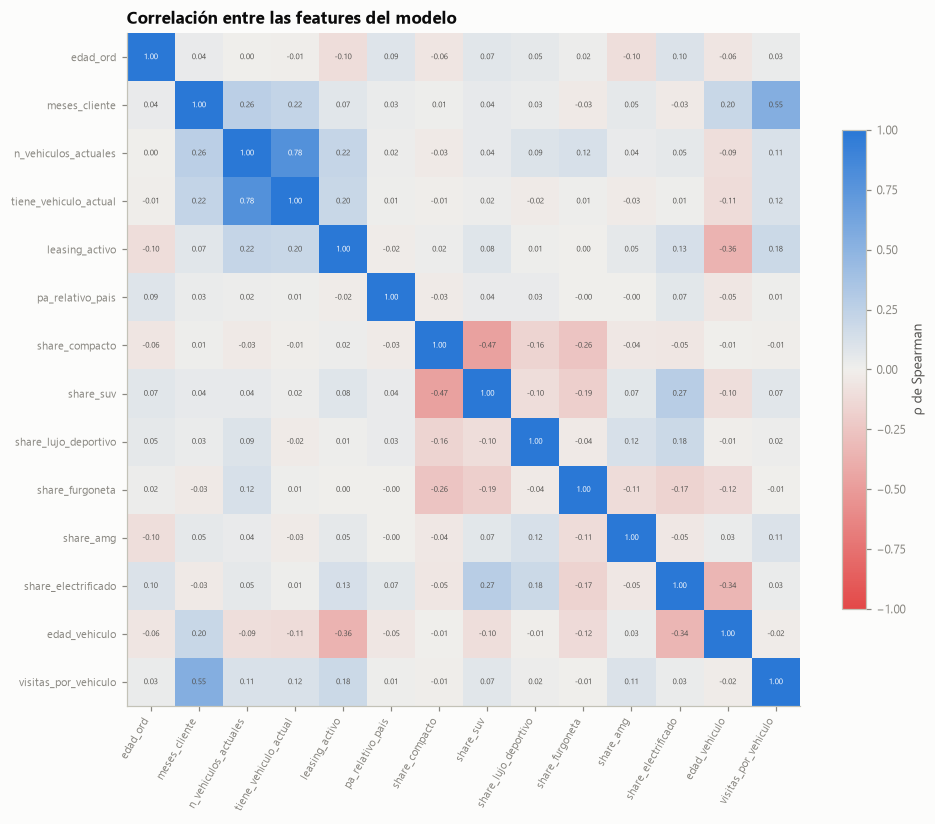

Pares con |ρ| > 0,8: 0


_Ninguno._

In [8]:
corr = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
import matplotlib.colors as mcolors
im = ax.imshow(corr.values, cmap=mcolors.LinearSegmentedColormap.from_list("div", DIV), vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=7.5); ax.set_yticklabels(corr.index, fontsize=7.5)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=5.5,
                color="white" if abs(corr.values[i, j]) > 0.6 else INK2)
fig.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman")
ax.set_title("Correlación entre las features del modelo")
save(fig, "r2_correlacion_features.png")
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pares = pares[pares.abs() > 0.8]
print("Pares con |ρ| > 0,8:", len(pares))
display(pares.to_frame("ρ") if len(pares) else Markdown("_Ninguno._"))

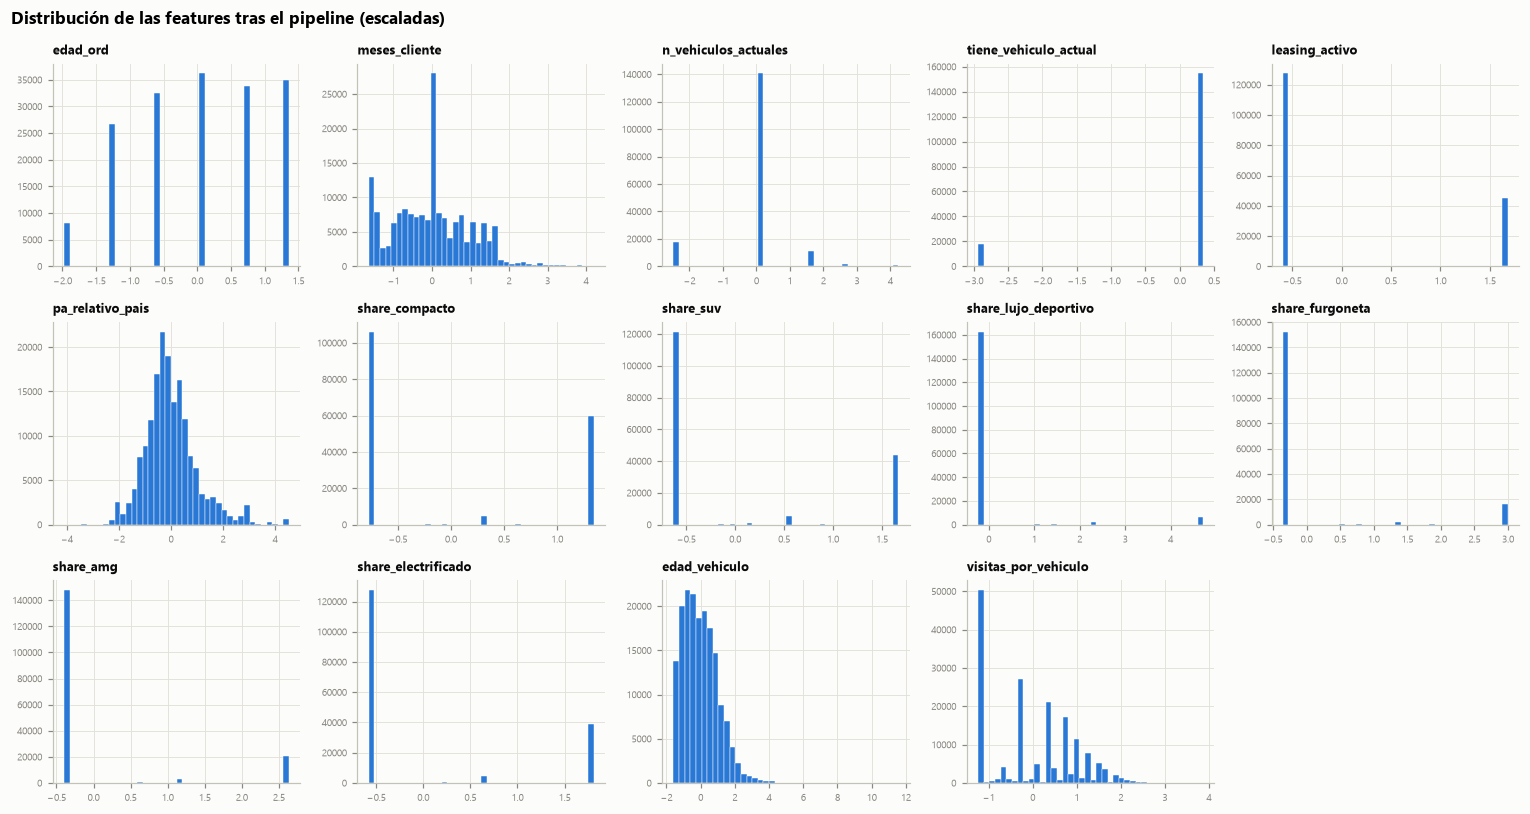

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(14, 7.5))
for ax, c in zip(axes.flat, FEATURES):
    ax.hist(X[c], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
    ax.set_title(c, fontsize=8.5)
    ax.tick_params(labelsize=6.5)
for ax in axes.flat[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Distribución de las features tras el pipeline (escaladas)", x=0.01, ha="left", fontsize=11, fontweight="bold")
save(fig, "r2_distribucion_features.png")

## 6. Exportación

In [10]:
X.to_csv(PROC / "features_modelo.csv")
legibles = construir_features(clientes)
cols_perfil = ["age_range", "gender_derived", "country_code", "finance_leasing_status", "familia_principal",
               "rol_principal", *[c for c in clientes.columns if c.startswith("consent_")],
               "n_relaciones", "n_vehiculos_distintos", "meses_desde_ultima_matriculacion",
               "share_bev", "share_phev", "share_mhev", "share_combustion", "share_diesel", "share_4matic",
               "share_medio", "speed_average", "fuel_consumption_average", "visitas_taller_total",
               "purchasing_power_per_inhabitant_eur", "is_b2b", "grupo"]
clientes_modelo = legibles.join(clientes[cols_perfil])
clientes_modelo.to_csv(PROC / "clientes_modelo.csv")
print(f"features_modelo.csv: {X.shape} · clientes_modelo.csv: {clientes_modelo.shape}")

features_modelo.csv: (172623, 14) · clientes_modelo.csv: (173456, 44)


## Resumen

- **Población:** se segmentan los clientes con 20 relaciones o menos. Las 833 flotas o profesionales forman un segmento aparte.
- **14 features de modelo** que cubren cuatro ejes: perfil y relación con la marca (5), valor y gama (6), energía y vehículo (2) y mantenimiento (1). Otras 5 (telemetría, país y leasing pasado) se reservan para el perfilado.
- **Features derivadas:** antigüedad del vehículo, poder adquisitivo relativo al país, situación de leasing, proporción de gama alta, proporción electrificada y visitas por vehículo.
- **Codificación:** ordinal para la edad, binarias (one-hot) para país y leasing, proporciones para la gama y la motorización.
- **Transformación:** log1p en las variables asimétricas y `StandardScaler` en todas, encapsulado en un `Pipeline` de scikit-learn.